# **Mapping short-let pressure in Bristol: A neighbourhood analysis of Airbnb listings**

# EDA objectives 

**Core question:** 

Where in Bristol are professional short-let operators concentrated, and how do their listings differ from those of casual hosts?

**Our definitions:**

- Operator listing: the host has 3 or more listings in this dataset. The sensitivity check uses 5 or more.
- Casual listing: the host has 1 or 2 listings.
- Concentration: the share of an area’s listings that are operator listings.

Main analysis subset: active listings (2,561). The robustness check uses current-scrape listings only (2,227).

**The questions we are exploring:**

H1: concentration varies by area.

The operator share is not the same across the 34 neighbourhoods.

- Null: any differences are no bigger than chance.
- Test: chi-square on area against operator status. All 34 areas were used.
- Charts: V2 (bar) and V3 (map).

H2: operator listings behave differently.

Compared with casual hosts, operator listings have higher annual availability and different minimum-stay requirements, as full-time commercial lettings would.

- Null: no difference.
- Test: Mann-Whitney on availability_365 and minimum_nights, reported with an effect size. Rank-based, because both are heavily skewed.
- Charts: V4 and V5.

H3: operator listings are rated differently.

Review scores differ between operator and casual listings. An early check suggested operators score lower.
- Null: no difference.
- Test: Mann-Whitney on review_scores_rating, with an effect size.
- Caveat: this uses only the 2,322 reviewed listings, so it describes reviewed listings, not all of them.
- Chart: V6.


# Change working directory

In [2]:
import os
current_dir = os.getcwd()
current_dir

'c:\\Users\\chheb\\OneDrive\\Documents\\Programming\\Mapping_Short_Let-Pressure_in_Bristol\\jupyter_notebooks'

In [3]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


In [4]:
current_dir = os.getcwd()
current_dir

'c:\\Users\\chheb\\OneDrive\\Documents\\Programming\\Mapping_Short_Let-Pressure_in_Bristol'

# Import transformed data

In [5]:
import json
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

In [6]:
df = pd.read_csv("data/processed/listings_clean.csv", dtype={"id": str},
                 parse_dates=["first_review", "last_review"])
print(df.shape)

(2932, 51)


# Exploring the data


## Neighbourhood table ##

**Purpose.** Hypothesis H1 and the map and bar charts need one row per neighbourhood. This table summarises the active listings (2,561) for each of the 34 areas, using the main-analysis subset decided in the transformation stage.

**Columns.** Listing counts, operator share at 3+ and 5+ listings, entire-home share, and median availability, minimum stay and rating.

**Checks.** 34 areas, 2,561 listings in total, and an overall operator share that matches the active-only figure from step 2 (about 42%).

**Caution.** 5 areas have fewer than 30 listings, so their shares are unstable. They are flagged in `small_area` and shown with their counts in the charts. The 30-listing cut-off is a judgement.

In [7]:
active = df[df["is_active"]]            
g = active.groupby("neighbourhood_cleansed")

area = pd.DataFrame({
    "listings": g.size(),
    "operator_listings": g["is_operator"].sum(),
    "operator_share": g["is_operator"].mean(),
    "operator_share_5": g["is_operator_5"].mean(),
    "entire_home_share": g["is_entire_home"].mean(),
    "median_availability_365": g["availability_365"].median(),
    "median_min_nights": g["minimum_nights"].median(),
    "median_rating": g["review_scores_rating"].median(),
})
area["all_listings"] = df.groupby("neighbourhood_cleansed").size()    
area["small_area"] = area["listings"] < 30                            
area = area.round(3)




In [8]:
print(len(area))                                                       
print(area["listings"].sum())                                          
print((area["operator_listings"].sum() / area["listings"].sum()).round(3))   
print("Small areas:", area["small_area"].sum())                        

area.sort_values("operator_share", ascending=False).head(10)

34
2561
0.42
Small areas: 5


,listings,operator_listings,operator_share,operator_share_5,entire_home_share,median_availability_365,median_min_nights,median_rating,all_listings,small_area
neighbourhood_cleansed,,,,,,,,,,
Central,231,146,0.632,0.515,0.853,281.0,1.0,4.720,254,False
Clifton Down,166,102,0.614,0.476,0.886,264.5,2.0,4.835,176,False
Lawrence Hill,119,70,0.588,0.513,0.807,260.0,1.0,4.750,142,False
Hotwells & Harbourside,104,59,0.567,0.510,0.913,294.0,2.0,4.750,111,False
Horfield,76,42,0.553,0.382,0.487,198.5,2.0,4.840,83,False
Cotham,112,54,0.482,0.357,0.741,209.5,2.0,4.830,130,False
Clifton,173,78,0.451,0.364,0.931,246.0,2.0,4.810,205,False
Southville,133,58,0.436,0.353,0.692,155.0,2.0,4.880,153,False
Ashley,273,118,0.432,0.311,0.700,160.0,2.0,4.870,314,False


This table shows us three important things for our analysis straight away:

- The spread is large. Operator share is 63.2% in Central and 61.4% in Clifton Down, against a Bristol average of about 42%. This already supports the idea behind H1, though it needs confirming through the chi-square test.
- Stockwood is an example of how small-area could be misleading. It sits in the top ten at 42.9%, but that is 6 of 14 listings. One more or fewer operator listing moves it by about 7 points. This is why V2 shows the count for each bar.
- Operators aren’t only entire homes. Horfield has a 55.3% operator share but only 48.7% entire homes, against 85% to 93% in the other top areas. A different kind of operator activity may be happening there.

## V0: Distributions ##

We need to explore whether the main listing measures evenly spread, or dominated by a few extreme values. The answer is crucial for deciding which summaries and statistical tests are appropriate for the rest of the analysis.

I plotted a histogram for each of four measures across the 2,561 active listings: 
- `price` 
- `minimum_nights`
- `availability_365`
- `calculated_host_listings_count` 

On each, the mean (dashed line) and median (solid line) are marked, and a table reports the mean, median and skewness.

I choose these four measures because they are the ones the hypotheses and the model will rely on. Price and availability describe how a listing is run, minimum stay is tested in H2, and the host listing count defines an operator.


                                  mean  median  skewness
price                           157.22   130.0      5.95
minimum_nights                    3.54     2.0     14.75
availability_365                202.20   239.0     -0.25
calculated_host_listings_count   13.54     2.0      3.10


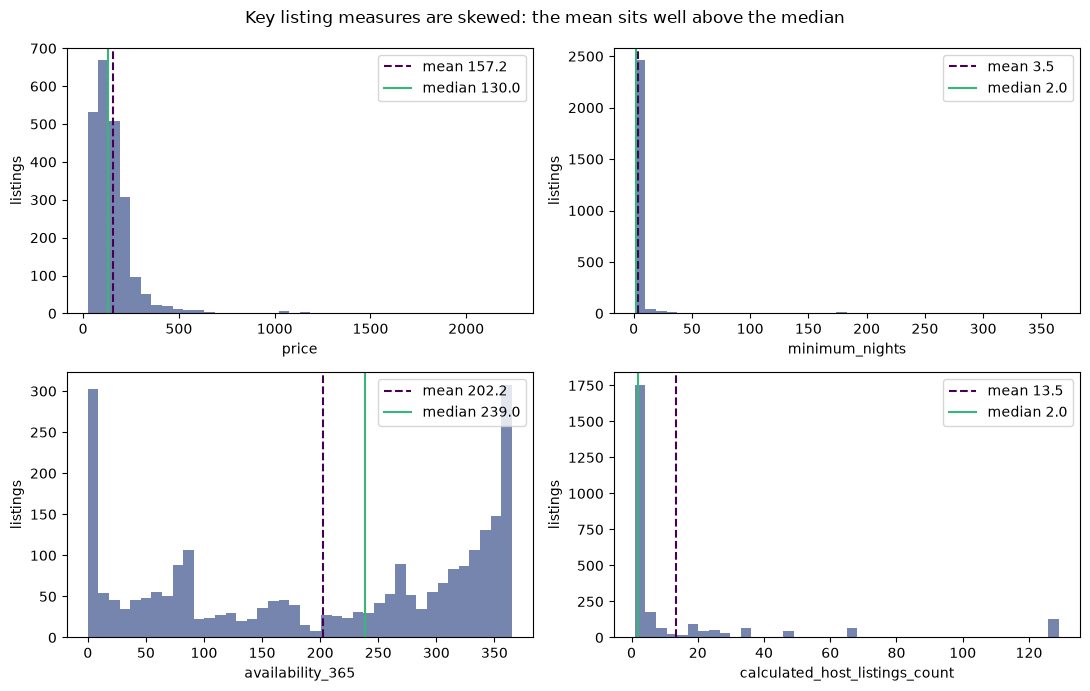

In [9]:
skew_cols = ["price", "minimum_nights", "availability_365", "calculated_host_listings_count"]
print(pd.DataFrame({"mean": active[skew_cols].mean(),
                    "median": active[skew_cols].median(),
                    "skewness": active[skew_cols].skew()}).round(2))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), skew_cols):
    data = active[col].dropna()
    ax.hist(data, bins=40, color="#3b528b", alpha=0.7)
    ax.axvline(data.mean(), color="#440154", linestyle="--", label=f"mean {data.mean():.1f}")
    ax.axvline(data.median(), color="#35b779", linestyle="-", label=f"median {data.median():.1f}")
    ax.set_xlabel(col); ax.set_ylabel("listings"); ax.legend()
fig.suptitle("Key listing measures are skewed: the mean sits well above the median")
plt.tight_layout()
plt.show()


- Three of the four measures are strongly right-skewed (skewness well above 1). A small number of extreme values pull the mean above the median: a few very expensive properties, a few listings that require a month or more (up to 365 nights), and a few hosts with dozens of listings, the largest with 129.
- `availability_365` is different. Its skewness is close to zero and its mean sits slightly below its median, so it is not dominated by extreme values. few listings sit at exactly 365 days (2.6% to 3.3%) but many sit close to it, so the right-hand cluster is “most of the year”, not “fully open”..

**What this means for the analysis**

- For skewed measures the mean is a poor summary of a typical listing, so we report medians when describing one.
- The comparisons in H2 and H3 use rank-based tests (Mann-Whitney), which compare the order of values and are not distorted by a few extremes. A t-test, which compares means, would be. For availability the case is weaker, because it is not skewed. A rank-based test is still appropriate because it does not assume the values follow a bell-shaped curve.
- Log-transforming was considered for the skewed measures. It does not suit minimum stay, which is mostly one to three nights. Where a chart needs to show a long tail (for example price), a log axis is used and labelled.

It is important to note that skew shows that extreme values exist, not that they are errors. The extremes checked in the outlier step of our ETL process were genuine listings, so they stay in the data.

## V1: What is the market's composition? ##

Our next task is getting a clearer picture of what is the market made of. In particular, we want to know whether operator and casual listings differ in the type of property they offer?

I used a a stacked bar chart to compare the room-type mix of operator listings (hosts with 3 or more listings, n=1,075) and casual listings (1 to 2 listings, n=1,486) among active listings. This means the two groups are comparable despite thier different sizes.

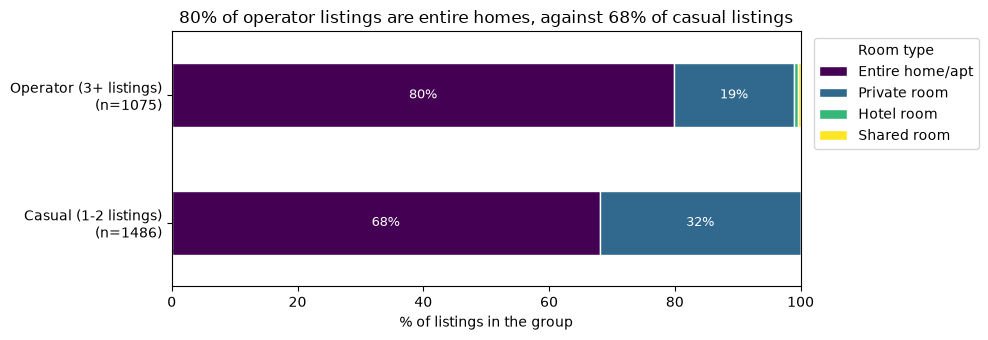

In [10]:
labels = {True: "Operator (3+ listings)", False: "Casual (1-2 listings)"}
group = active["is_operator"].map(labels)
order = ["Entire home/apt", "Private room", "Hotel room", "Shared room"]

comp = pd.crosstab(group, active["room_type"], normalize="index")[order] * 100
n = group.value_counts()

ax = comp.plot(kind="barh", stacked=True, figsize=(10, 3.5), colormap="viridis", edgecolor="white")
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0f}%" if v >= 4 else "" for v in c.datavalues],
                 label_type="center", color="white", fontsize=9)

ax.set_yticklabels([f"{g}\n(n={n[g]})" for g in comp.index])
ax.set_xlabel("% of listings in the group")
ax.set_ylabel("")
op_home = comp.loc[labels[True], "Entire home/apt"]
cas_home = comp.loc[labels[False], "Entire home/apt"]
ax.set_title(f"{op_home:.0f}% of operator listings are entire homes, against {cas_home:.0f}% of casual listings")
ax.legend(title="Room type", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

  

In [11]:
comp.round(1)  

room_type,Entire home/apt,Private room,Hotel room,Shared room
is_operator,,,,
Casual (1-2 listings),68.0,32.0,0.0,0.0
Operator (3+ listings),79.9,19.0,0.7,0.5


In [12]:
active.groupby("room_type")["is_operator"].agg(["size", "mean"]).round(3)

,size,mean
room_type,,
Entire home/apt,1870,0.459
Hotel room,7,1.000
Private room,679,0.300
Shared room,5,1.000


- Entire homes make up the majority in both groups. But this definitely more the case for operators, with entire homes making up 80% of their listings (compared to 68% of casual listings).
- Private rooms make up 19% of operator listings and 32% of casual listings.
- Hotel and shared rooms are under 1% of either group.

**What this means for Bristol City Council.** 

Operator activity is concentrated in entire homes, the property type most likely to be taken out of long-term housing. We can see that operators hold about 46% of all active entire-home listings. However,  the data cannot show whether those homes were previously rented to residents.

**Limitations:** 

The chart shows the mix within each group, not the share of each room type that operators hold. "Casual" includes hosts with two listings, and the 3-listing threshold is a judgement call. This is a description, not a test. In reality, it does not show that the difference is more than chance.

## V2: Are operators concentrated in certain areas?

An important part of our understanding of the data is seeing if professional operators are concentrated in certain areas? This is the basis of H1.

I calculated the share of active listings run by operators (hosts with 3 or more listings) in each of the 34 neighbourhoods, and ranked them. Bar labels show the number of active listings behind each share, and areas with fewer than 30 listings are shaded grey.

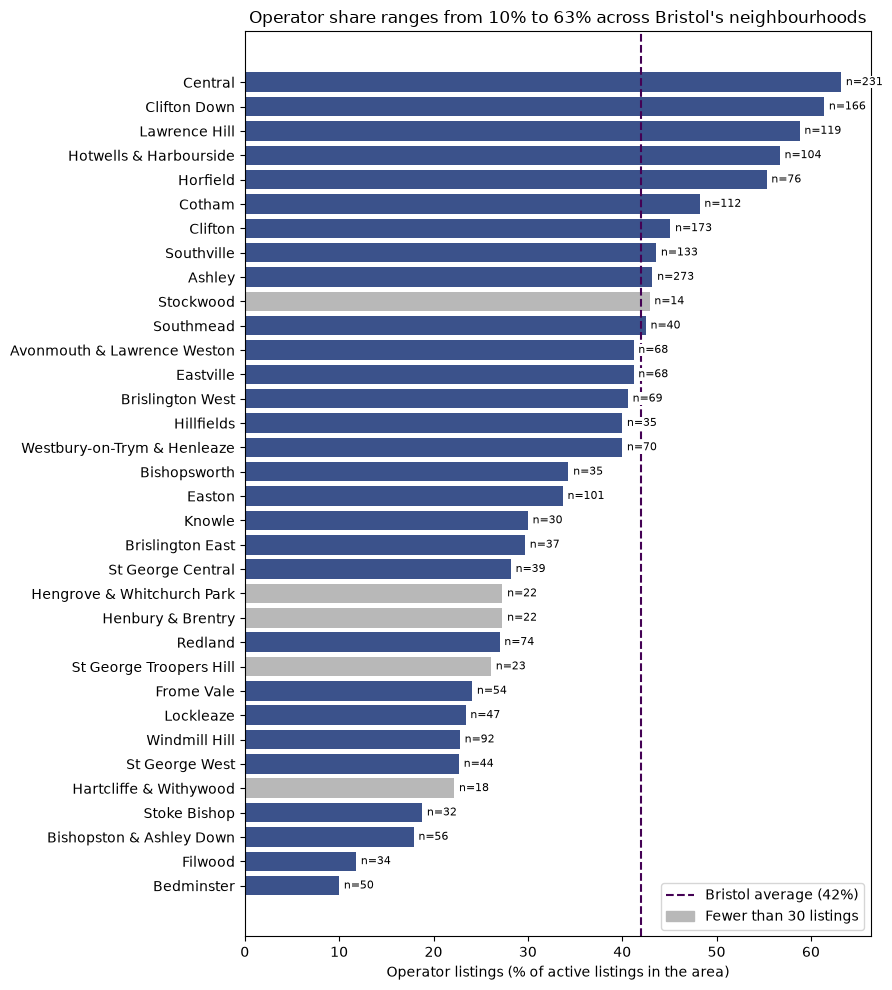

In [13]:
from matplotlib.patches import Patch

plot = area.reset_index().sort_values("operator_share")
overall = active["is_operator"].mean() * 100
lo, hi = plot["operator_share"].min() * 100, plot["operator_share"].max() * 100

fig, ax = plt.subplots(figsize=(9, 10))
colors = np.where(plot["small_area"], "#b8b8b8", "#3b528b")        # grey = fewer than 30 listings
ax.barh(plot["neighbourhood_cleansed"], plot["operator_share"] * 100, color=colors)
ax.axvline(overall, color="#440154", linestyle="--", label=f"Bristol average ({overall:.0f}%)")

for y, (share, n) in enumerate(zip(plot["operator_share"], plot["listings"])):
    ax.text(share * 100 + 0.5, y, f"n={n}", va="center", fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5))   # keeps labels readable over the line

ax.set_xlabel("Operator listings (% of active listings in the area)")
ax.set_title(f"Operator share ranges from {lo:.0f}% to {hi:.0f}% across Bristol's neighbourhoods")

handles, _ = ax.get_legend_handles_labels()
handles.append(Patch(color="#b8b8b8", label="Fewer than 30 listings"))
ax.legend(handles=handles)

plt.tight_layout()
plt.show()


- Operator share varies widely, from 10% in Bedminster to 63% in Central, against a Bristol average of 42%.
- Four areas (Central, Clifton Down, Lawrence Hill, Hotwells & Harbourside) have shares above 55%. Together they hold 24% of active listings but 35% of operator listings.
- Most areas are below the Bristol average. The average is pulled up by a small number of large, high-share areas.

**What this means for Bristol City Council.** 

Operator activity is not spread evenly. A small number of areas account for a disproportionate share of it, so any attention to professional short-lets would reach more of it by starting there.

**Limitations:**

- Five areas have fewer than 30 listings, and several more have 30 to 40, so their shares are unstable. The 30-listing cut-off is a judgement.
- The chart shows the size of the differences, not whether they are more than chance.
- We can show where operator listings are, but not whether they are a direct cause of housing pressure.

# V3: Can we show that concentration on a map?

To explore H1, we can show geographically the cluster of operator activity in particular places. 

Coloured each of the 34 neighbourhoods by its operator share (the percentage of active listings run by hosts with 3 or more listings), using the council boundary file. Hovering over an area shows its listing count and flags areas with fewer than 30 listings.

In [14]:
import shutil
Path("data/processed").mkdir(parents=True, exist_ok=True)
shutil.copy("data/raw/neighbourhoods.geojson", "data/processed/neighbourhoods.geojson")

'data/processed/neighbourhoods.geojson'

In [ ]:
with open("data/processed/neighbourhoods.geojson", encoding="utf-8") as f:
    geo = json.load(f)

map_df = area.reset_index()
map_df["operator_pct"] = (map_df["operator_share"] * 100).round(1)

fig = px.choropleth(
    map_df,
    geojson=geo,
    locations="neighbourhood_cleansed",
    featureidkey="properties.neighbourhood",
    color="operator_pct",
    color_continuous_scale="Viridis",
    hover_name="neighbourhood_cleansed",
    hover_data={"neighbourhood_cleansed": False, "operator_pct": ":.1f",
                "listings": True, "small_area": True},
    labels={"operator_pct": "Operator share (%)", "listings": "Active listings",
            "small_area": "Fewer than 30 listings"},
)
fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(
    title="Operators are clearly concentrated in the centre of the city",
    margin=dict(l=0, r=0, t=60, b=0),
    height=600,
)
fig.show()

**What we found**
- Operator share is highest in the central part of the city and neighbouring areas, including Central (63%) and Clifton Downshares (61%).
- Shares fall towards the outer areas, and are lowest in the south of the city, particuarly in Bedminster (10%) and Filwood (12%).
- High-share areas sit next to each other, so the pattern is geographic and not scattered.

**What this means for the Bristol City Council** 

Operator activity clusters in a connected central area. A response aimed at professional short-lets could be targeted geographically, not citywide.

**Limitations**

- The map gives every area the same visual weight whatever its size or number of listings, so large areas with few listings can look more important than they are. It should be read alongside V2, which shows the counts.
- Areas with few listings (shaded grey in V2) are coloured like any other, and their shares are unstable.
- Again, we can only describe where operator listings are, not whether they affect housing.

# V4: Is there a difference in availability between operators and casuals?

We can now start to test H2 -  that operator and casual listings differ in terms of availability.

stat="percent" with common_norm=False scales each group to 100% on its own. The groups have different sizes (1,075 against 1,486), so raw counts would make them hard to compare. bins=37 gives bars about 10 days wide.

The dashed lines mark each group’s median, and the title is built from the data so it states the finding.

In [ ]:
labels = {True: "Operator (3+ listings)", False: "Casual (1-2 listings)"}
group = active["is_operator"].map(labels)
palette = {labels[True]: "#440154", labels[False]: "#35b779"}

active.groupby(group)["availability_365"].describe()[["count", "25%", "50%", "75%"]]

med_op = active.loc[active["is_operator"], "availability_365"].median()
med_cas = active.loc[~active["is_operator"], "availability_365"].median()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=active, x="availability_365", hue=group, bins=37, stat="percent",
             common_norm=False, element="step", alpha=0.35, palette=palette, ax=ax)
for lab, color in palette.items():
    ax.axvline(active.loc[group == lab, "availability_365"].median(), color=color, linestyle="--")

ax.set_xlabel("Days available in the next 365 (dashed line = group median)")
ax.set_ylabel("% of listings in the group")
ax.set_title(f"Operator listings are open a median {med_op:.0f} days a year, against {med_cas:.0f} for casual listings")
plt.tight_layout()
plt.show()

NameError: name 'active' is not defined

In [ ]:
# 1. Exact shares at the extremes (fills the open V0 availability placeholder)
extremes = active.groupby(group)["availability_365"].agg(
    zero=lambda s: (s == 0).mean(),
    full_year=lambda s: (s == 365).mean(),
).round(3)
print(extremes)

# 2. Robustness: same medians on current-scrape listings only
current = active[~active["from_previous_scrape"]]
print(current.groupby(current["is_operator"].map(labels))["availability_365"].median())

                         zero  full_year
is_operator                             
Casual (1-2 listings)   0.093      0.026
Operator (3+ listings)  0.076      0.033
is_operator
Casual (1-2 listings)     241.0
Operator (3+ listings)    303.5
Name: availability_365, dtype: float64


We can see that both groups are U-shaped: a pile of listings with no availability (9.3% of casual and 7.6% of operator listings are at exactly 0 days) and a larger pile open for most of the year. Operator listings lean towards the second group (median 281 days against 195 for casual hosts).

**What it means for the council:** 

Operator listings are open more days a year, which fits H2's idea that they behave more like full-time commercial lettings. The gap is 86 days on all active listings and 62.5 days on current-scrape listings only (303.5 against 241), so the direction is stable but the size depends on the subset. 

**Limitations:** 

Availability is what a host leaves open, not how often the listing is booked. A calendar open most of the year can mean a full-time let or an unmanaged calendar. Listings with no availability may be dormant or blocked off, rather than rarely used. Previous-scrape listings may have stale calendars, which is why the current-scrape check is important.



# V5: Is there a difference in minimum stays between operators and casuals?

Looking at whether operator listings set different minimum-stay requirements from casual listings is the the second half of H2, alongside availability (V4).

The minimum nights is very skewed (median 2, mean 3.5, skewness 14.75), so a histogram would show one tall bar at 1-3 nights and an unreadable tail. Instead, listings are grouped into bands: 1, 2, 3, 4-6, 7-29 and 30+ nights. The 30-night edge matches the `is_short_stay` feature from the transformation stage. The chart shows the percentage of each host type's listings in each band, so the groups can be compared despite their different sizes (1,075 operator listings against 1,485 casual).

This uses active listings only. One active listing has no minimum-nights value and is excluded from the bands.

minimum_nights            1    2    3  4-6  7-29  30+
is_operator                                          
Casual (1-2 listings)   620  534  132  105    76   18
Operator (3+ listings)  513  360   68   50    71   13
minimum_nights             1     2    3  4-6  7-29  30+
is_operator                                            
Casual (1-2 listings)   41.8  36.0  8.9  7.1   5.1  1.2
Operator (3+ listings)  47.7  33.5  6.3  4.7   6.6  1.2


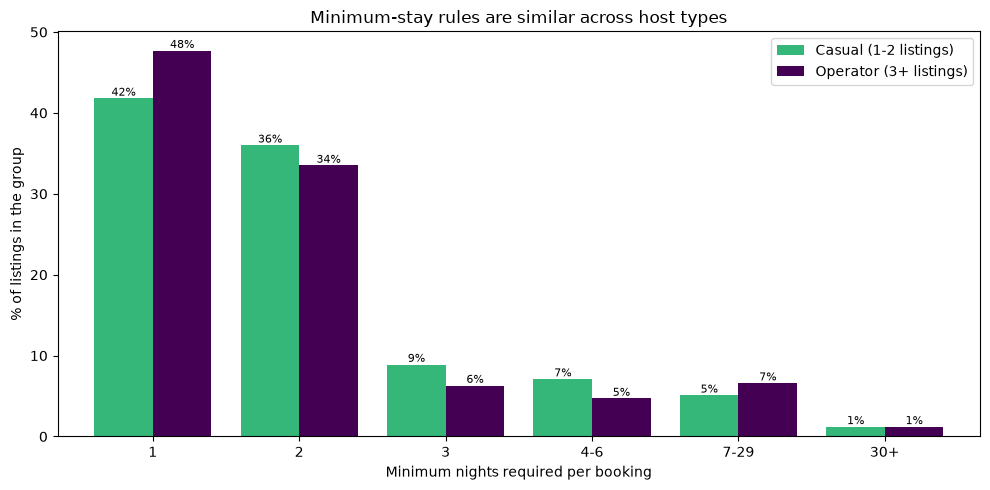

In [ ]:
labels = {True: "Operator (3+ listings)", False: "Casual (1-2 listings)"}
group = active["is_operator"].map(labels)
palette = {labels[True]: "#440154", labels[False]: "#35b779"}

bands = pd.cut(active["minimum_nights"], bins=[0, 1, 2, 3, 6, 29, np.inf],
               labels=["1", "2", "3", "4-6", "7-29", "30+"])

counts = pd.crosstab(group, bands)                          # n per cell
share = (pd.crosstab(group, bands, normalize="index") * 100).round(1)
print(counts)
print(share)

short = share[["1", "2"]].sum(axis=1)                       # % requiring 1-2 nights

fig, ax = plt.subplots(figsize=(10, 5))
share.T.plot(kind="bar", ax=ax, color=[palette[c] for c in share.index], width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", fontsize=8)
ax.set_xlabel("Minimum nights required per booking")
ax.set_ylabel("% of listings in the group")
ax.set_title("Minimum-stay rules are similar across host types")
ax.tick_params(axis="x", rotation=0)
ax.legend(title=None)
plt.tight_layout()
plt.show()

The two host types are broadly similar when it comes to minimum nights. Both are concentrated at 1-2 nights (81% of operator listings, 78% of casual listings). The clearest difference is at 1 night: 48% of operator listings against 42% of casual.

**What it means for Bristol City Council:** 

Minimum stay barely separates the two groups. Unlike availability (V4), minimum stay is not a strong signal of professional operation.

**Limitations:** 

Minimum stay is a host setting that can change by season, and one listing has no value. The 30+ band holds only 31 listings in total (18 casual, 13 operator), so its percentages are unreliable. The band edges are a judgement call.

# V6: Are operator listings rated differently?

Another core question is whether operator listings rated differently from casual listings? 

Ratings are capped at 5 and bunched near the top, so the distribution is skewed to the left and a mean would be pulled down by a few poor ratings. The chart overlays the rating distribution for each host type as a percentage of that group, so the groups can be compared despite their different sizes. Dashed lines mark the group medians.

Active listings that have a rating (1,348 casual and 974 operator listings). Listings with no rating are excluded, not filled in, because there is nothing to compare. Before charting, I checked that the groups are comparable on coverage: 90.7% of casual and 90.6% of operator listings have a rating.

                         count     25%    50%  75%
is_operator                                       
Casual (1-2 listings)   1348.0  4.8000  4.920  5.0
Operator (3+ listings)   974.0  4.4725  4.745  4.9
is_operator
Casual (1-2 listings)     0.907
Operator (3+ listings)    0.906
Name: review_scores_rating, dtype: float64


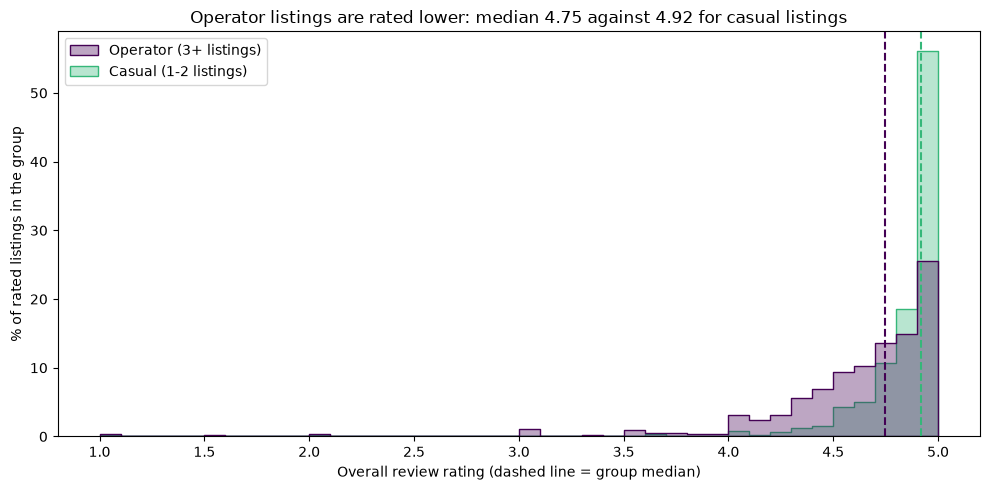

In [ ]:
labels = {True: "Operator (3+ listings)", False: "Casual (1-2 listings)"}
group = active["is_operator"].map(labels)
palette = {labels[True]: "#440154", labels[False]: "#35b779"}

rated = active[active["review_scores_rating"].notna()]
rgroup = rated["is_operator"].map(labels)

# Figures behind the chart
print(rated.groupby(rgroup)["review_scores_rating"].describe()[["count", "25%", "50%", "75%"]])

# How many listings in each group have a rating at all?
print(active.groupby(group)["review_scores_rating"].apply(lambda s: s.notna().mean()).round(3))

med_op = rated.loc[rated["is_operator"], "review_scores_rating"].median()
med_cas = rated.loc[~rated["is_operator"], "review_scores_rating"].median()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=rated, x="review_scores_rating", hue=rgroup, binwidth=0.1, stat="percent",
             common_norm=False, element="step", alpha=0.35, palette=palette, ax=ax)
for lab, color in palette.items():
    ax.axvline(rated.loc[rgroup == lab, "review_scores_rating"].median(), color=color, linestyle="--")

ax.set_xlabel("Overall review rating (dashed line = group median)")
ax.set_ylabel("% of rated listings in the group")
ax.set_title(f"Operator listings are rated lower: median {med_op:.2f} against {med_cas:.2f} for casual listings")
ax.get_legend().set_title(None)
plt.tight_layout()
plt.show()

In [ ]:
# Do the groups differ in how many reviews sit behind each rating?
print(rated.groupby(rgroup)["number_of_reviews"].median())

# Does the gap survive when we only look at well-reviewed listings?
for min_reviews in [1, 10]:        # 1 = all rated listings
    sub = rated[rated["number_of_reviews"] >= min_reviews]
    print(f"\nListings with {min_reviews}+ reviews")
    print(sub.groupby(sub["is_operator"].map(labels))["review_scores_rating"].agg(["count", "median"]))

is_operator
Casual (1-2 listings)     32.0
Operator (3+ listings)    22.0
Name: number_of_reviews, dtype: float64

Listings with 1+ reviews
                        count  median
is_operator                          
Casual (1-2 listings)    1348   4.920
Operator (3+ listings)    974   4.745

Listings with 10+ reviews
                        count  median
is_operator                          
Casual (1-2 listings)    1010    4.90
Operator (3+ listings)    666    4.73


We can clearly see that operators are rated lower. But I thought this may be a small-sample effect where a listing with two reviews can easily average 5.0. I also expected casual hosts to have fewer reviews, which would have inflated their ratings. The data shows the opposite with casual listings having a median of 32 reviews against 22 for operators. So the casual hosts’ high ratings aren’t a small-sample effect and the gap is real in the data. The median is 4.92 for casual listings and 4.75 for operator listings. The operator upper quartile (4.90) sits below the casual median, so the whole operator distribution is shifted down, not just its tail. Operator listings spread further across the 4.0-4.8 range.

**What it means for Bristol City Council:** 

Operator listings are rated lower than casual ones. This does not fit the idea that professional operators deliver a more consistent or higher-rated experience. This is the pattern H3 asks about, and the Mann-Whitney test and effect size will say whether the gap is meaningful. 

**Robustness:** 

The gap is not a review-count artefact. Casual listings have more reviews at the median (32 against 22), and the gap holds among listings with 10+ reviews (median 4.90 for casual and 4.73 for operator, against 4.92 and 4.75 on all rated listings).

**Limitations:** 

Ratings are compressed near the top of the scale, so small differences matter more than they would elsewhere. A rating ignores how many reviews sit behind it. Unreviewed listings are excluded and are probably newer, so this describes established listings only.

# V7: How does price differ between host types?

Price isn’t explicitly mentioned in H1-H3. But we need to checks whether room type is driving the operator differences. This will help us decide whether price belongs in the ML model.

Do operator and casual listings charge different prices, and is any difference explained by room type? V1 showed operators have more entire homes, and entire homes cost more, so a plain price comparison could be misleading. 

Price is also highly skewed (mean 157, median 130, skewness 5.95), so the chart uses box plots on a log scale, which show the median and spread without a few expensive listings dominating. Box plots are split by room type so the host-type comparison is made within each type.

I only use active listings with a price. The chart shows entire homes and private rooms, which hold nearly all listings. Hotel and shared rooms appear in the printed table only, because their cell sizes are small. Also, it is important to note that price is the advertised price, not what guests paid.

                                        count  median
room_type       is_operator                          
Entire home/apt Casual (1-2 listings)     889   154.0
                Operator (3+ listings)    762   164.0
Hotel room      Operator (3+ listings)      7   159.0
Private room    Casual (1-2 listings)     410    59.0
                Operator (3+ listings)    188    70.0
Shared room     Operator (3+ listings)      5   130.0


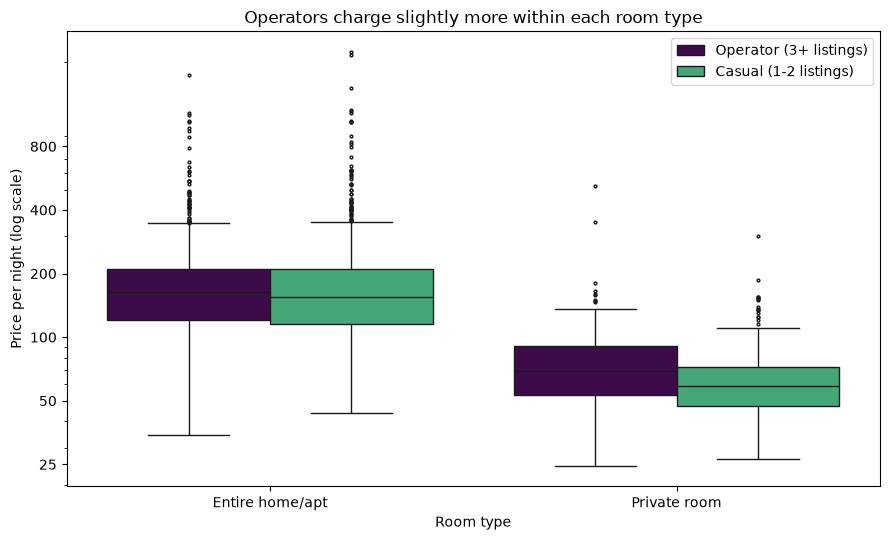

In [ ]:
from matplotlib.ticker import ScalarFormatter

labels = {True: "Operator (3+ listings)", False: "Casual (1-2 listings)"}
palette = {labels[True]: "#440154", labels[False]: "#35b779"}
main_types = ["Entire home/apt", "Private room"]

priced = active[active["price"].notna()]
pgroup = priced["is_operator"].map(labels)

# All four room types: counts and medians (check the small cells before trusting them)
print(priced.groupby(["room_type", pgroup])["price"].agg(["count", "median"]).round(0))

# Chart: the two main room types only
main = priced[priced["room_type"].isin(main_types)]
mgroup = main["is_operator"].map(labels)
med = main.groupby(["room_type", mgroup])["price"].median()
eh_op, eh_cas = med[("Entire home/apt", labels[True])], med[("Entire home/apt", labels[False])]

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=main, x="room_type", y="price", hue=mgroup, order=main_types,
            hue_order=[labels[True], labels[False]], palette=palette, fliersize=2, ax=ax)
ax.set_yscale("log")
ax.set_yticks([25, 50, 100, 200, 400, 800])
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.set_xlabel("Room type")
ax.set_ylabel("Price per night (log scale)")
ax.set_title("Operators charge slightly more within each room type")
ax.legend(title=None)
plt.tight_layout()
plt.show()

 Within entire homes the median is 164 for operator listings and 154 for casual (about 6% higher). Within private rooms it is 70 against 59 (about 19% higher). The boxes overlap heavily in both room types. Room type is the dominant driver of price: entire homes sit around 150-165 and private rooms around 60-70, regardless of host type.

**What it means for Bristol City Council:** 

Operators price slightly higher than casual hosts in the same room type, but the difference is small relative to the spread within each group. Price is not a strong separator of host type, and the overall median (V0) mixes two very different products. None of our hypothesis actively tests price, so this is descriptive context only.

**Limitations:** 
Price is the advertised nightly price, not what guests paid. All 7 hotel rooms and 5 shared rooms belong to operators, so there is no casual comparison and they are left out of the chart. The gap is a difference in medians with no test or effect size.

# V8: Is there correlation between features?

This step looks at which model inputs overlap with each other, and which move with host type? This informs the feature set for the ML step and how far the logistic regression coefficients can be interpreted.

I used a Spearman rank correlation matrix, which is robust to skew and outliers. Host-count columns are excluded because they define the target, so including them would be circular. `is_operator` appears only so its row can be read. Correlations are computed pair by pair, so review-based columns use fewer listings than the others.

This uses active listings only as correlation measures steady one-direction relationships only. A low value does not rule out a feature that works in other ways (for example, a U-shaped pattern), and it says nothing about causes.

Not found: []
beds          accommodates    0.90
              bedrooms        0.85
bedrooms      accommodates    0.83
accommodates  price           0.78
beds          price           0.71
dtype: float64
review_scores_rating   -0.36
number_of_reviews      -0.11
host_is_superhost      -0.11
minimum_nights         -0.06
bedrooms               -0.02
beds                    0.08
accommodates            0.09
is_entire_home          0.13
price                   0.15
availability_365        0.15
Name: is_operator, dtype: float64


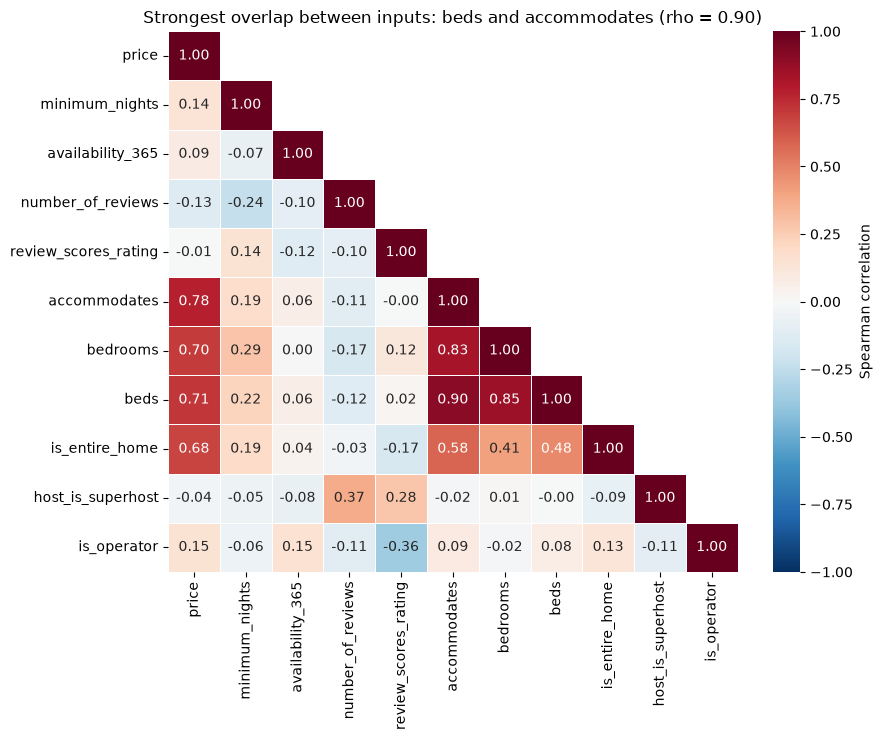

In [ ]:
# Host-count columns are deliberately excluded: they define the target, so they would be circular
candidates = ["price", "minimum_nights", "availability_365", "number_of_reviews",
              "review_scores_rating", "accommodates", "bedrooms", "beds",
              "is_entire_home", "host_is_superhost", "is_operator"]
cols = [c for c in candidates if c in active.columns]
print("Not found:", [c for c in candidates if c not in active.columns])

corr = active[cols].astype(float).corr(method="spearman")   # pairwise: missing values dropped per pair

# Strongest overlaps between inputs (target excluded)
inputs = corr.drop(index="is_operator", columns="is_operator")
pairs = inputs.where(np.tril(np.ones(inputs.shape, dtype=bool), k=-1)).stack()
top = pairs.abs().sort_values(ascending=False).head(5)
print(pairs.loc[top.index].round(2))

# Association of each feature with the target
print(corr["is_operator"].drop("is_operator").sort_values().round(2))

a, b = pairs.abs().idxmax()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title(f"Strongest overlap between inputs: {a} and {b} (rho = {pairs[(a, b)]:.2f})")
plt.tight_layout()
plt.show()

The three size variables overlap heavily (`beds`-`accommodates` 0.90, `beds`-`bedrooms` 0.85, `bedrooms`-`accommodates` 0.83), and price follows them (0.70-0.78). This seems to suggest that price is partly a proxy for size. 

The strongest association with host type is review rating (-0.36), followed by price and availability (both 0.15), entire home (0.13), review count and superhost status (both -0.11) and minimum nights (-0.06).

**What it means for Bristol City Council:** 

No single feature separates operator from casual listings strongly. The clearest signal is that operator listings tend to have lower ratings, which matches V6. The other associations are weak, which matches the modest differences in V4, V5 and V7. A classifier should be judged against the baseline of always predicting the larger group.

**Decision for the model:** 

`beds` and `bedrooms` are dropped because they correlate 0.85-0.90 with `accommodates`, which is kept as the single size measure. Both models use the same feature set.

Price is retained in the initial model. It will be removed in a cross-validated ablation to test whether it adds anything beyond size.

**Limitations:** 
Spearman captures steady one-direction relationships only, so a weak value does not rule out a feature that works in other ways (e.g. availability was U-shaped in V4). Review-based columns use rated listings only. This correlation also obviously says nothing about causes.

# V9: Do the findings depend on the definition of operators?

This step is a robustness check on H1-H3 before the formal tests.

The V4 (availability) and V6 (rating) comparisons are repeated under two operator definitions (3+ listings, and a stricter 5+) and three subsets: all listings, active listings, and active listings from the current scrape only. For each of the six scenarios the table reports the operator share and the operator-minus-casual gap in median availability and median rating. A rank correlation between the two definitions' neighbourhood operator shares checks whether the geography (H1) is stable.

I only used descriptive medians and no tests are run here. The check covers my own analytic choices, not variation between data snapshots.

                   subset definition     n  operator_share_%  \
0            All listings         3+  2932             38.51   
1            All listings         5+  2932             28.27   
2                  Active         3+  2561             41.98   
3                  Active         5+  2561             31.43   
4  Active, current scrape         3+  2227             42.57   
5  Active, current scrape         5+  2227             31.97   

   availability_gap_days  rating_gap  
0                  156.0       -0.17  
1                  173.0       -0.24  
2                   86.0       -0.17  
3                  110.5       -0.24  
4                   62.5       -0.16  
5                   73.0       -0.24  
                  operator_share  operator_share_5
operator_share              1.00              0.82
operator_share_5            0.82              1.00


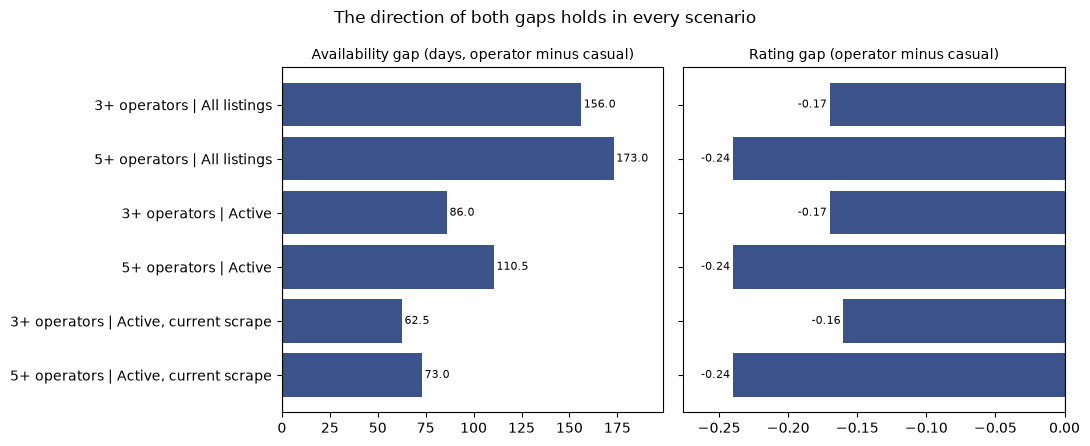

In [ ]:
subsets = {
    "All listings": df,
    "Active": active,
    "Active, current scrape": active[~active["from_previous_scrape"]],
}
definitions = {"3+": "is_operator", "5+": "is_operator_5"}

rows = []
for s_name, sub in subsets.items():
    for d_name, col in definitions.items():
        op, cas = sub[sub[col]], sub[~sub[col]]
        rows.append({
            "subset": s_name, "definition": d_name, "n": len(sub),
            "operator_share_%": len(op) / len(sub) * 100,
            "availability_gap_days": op["availability_365"].median() - cas["availability_365"].median(),
            "rating_gap": op["review_scores_rating"].median() - cas["review_scores_rating"].median(),
        })
sens = pd.DataFrame(rows).round(2)
sens["scenario"] = sens["definition"] + " operators | " + sens["subset"]
print(sens.drop(columns="scenario"))

# H1 sensitivity: do the two definitions rank neighbourhoods the same way?
print(area[["operator_share", "operator_share_5"]].corr(method="spearman").round(2))

holds = (sens["availability_gap_days"] > 0).all() and (sens["rating_gap"] < 0).all()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, col, title in zip(axes, ["availability_gap_days", "rating_gap"],
                          ["Availability gap (days, operator minus casual)",
                           "Rating gap (operator minus casual)"]):
    ax.barh(sens["scenario"], sens[col], color="#3b528b")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.bar_label(ax.containers[0], fmt="%.1f" if col == "availability_gap_days" else "%.2f",
                 padding=2, fontsize=8)
    ax.margins(x=0.15)
    ax.set_title(title, fontsize=10)
axes[0].invert_yaxis()
fig.suptitle("The direction of both gaps holds in every scenario" if holds
             else "The direction of at least one gap changes between scenarios")
plt.tight_layout()
plt.show()

Operators are open for more days and rated lower than casual hosts in all six scenarios (two operator definitions across three listing subsets). The size of the gaps varies. Availability gap: 62.5-173 days. Rating gap: -0.16 to -0.24. The stricter 5+ definition gives a larger gap than 3+ in every subset. Including inactive listings roughly doubles the availability gap (156 days against 86 on active listings), so active listings are used as the main subset. Neighbourhood operator shares under the two definitions have a rank correlation of 0.82.

**What it means for Bristol City Council:** 

The direction of the findings does not depend on the definition or subset chosen, so the conclusions are not an artefact of the 3+ threshold. 

The size of the availability gap does depend on the subset, so it as a range and uses the active, current-scrape figure (62.5 days) as the conservative estimate. The geography is mostly, but not fully, stable between definitions, so H1 is tested under both.

**Decisions:** 

Main analysis uses active listings and the 3+ definition. The 5+ definition and the current-scrape subset are reported as sensitivity checks.

**Limitations:** 

The six scenarios reuse the same listings, so they are not independent replications. The medians are shown without uncertainty; the formal tests follow. The check covers my own analytic choices, not variation between data snapshots.

## Testing the hypothesis 

### H1. Does operator share differ by neighbourhood?

 **Hypothesis**

 - Operator status is independent of neighbourhood. 
 - Operator share differs between neighbourhoods. Significance level 0.05.

**Method:** 
Chi-square test of independence on the neighbourhood by operator/casual table, using active listings. Cramér's V is reported as the effect size, because with this many listings almost any difference is statistically significant. The test is run on all 34 areas; no cell has an expected count below 5, so the chi-square condition is met. As a check, areas with fewer than 30 listings (the V2 cut-off) are also grouped together.

**Assumptions and limits:** 
Listings from the same host are not independent, and operators tend to cluster, which can inflate significance. To check how much one host matters, the test is repeated without the largest host.

In [ ]:
small = area.index[area["small_area"]]           # the <30-listing areas flagged in V2

def chi2_area(data, col, group_small):
    d = data.copy()
    d["area_used"] = d["neighbourhood_cleansed"]
    if group_small:
        d["area_used"] = d["area_used"].where(~d["area_used"].isin(small), "Other (small areas)")
    table = pd.crosstab(d["area_used"], d[col])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    return {"areas": table.shape[0], "chi2": round(chi2, 1), "dof": dof, "p": p,
            "cramers_v": round(v, 3), "cells_expected_below_5": int((expected < 5).sum()),
            "cells": expected.size}

top_host = active["host_key"].value_counts().index[0]
without_top = active[active["host_key"] != top_host]

runs = {
    "3+, areas grouped":            (active, "is_operator", True),
    "3+, all 34 areas":             (active, "is_operator", False),
    "5+, areas grouped":            (active, "is_operator_5", True),
    "3+, grouped, largest host out": (without_top, "is_operator", True),
}
h1 = pd.DataFrame({name: chi2_area(*args) for name, args in runs.items()}).T
print(h1)

                               areas   chi2   dof             p  cramers_v  \
3+, areas grouped               30.0  214.0  29.0  4.159495e-30      0.289   
3+, all 34 areas                34.0  215.6  33.0  1.111022e-28      0.290   
5+, areas grouped               30.0  240.8  29.0  3.049806e-35      0.307   
3+, grouped, largest host out   30.0  165.2  29.0  5.262034e-21      0.261   

                               cells_expected_below_5  cells  
3+, areas grouped                                 0.0   60.0  
3+, all 34 areas                                  0.0   68.0  
5+, areas grouped                                 0.0   60.0  
3+, grouped, largest host out                     0.0   60.0  


**Result:** 

We can reject the idea that operator status is independent of neighbourhood. Operator share differs significantly by neighbourhood (χ² = 215.6, 33 d.f., p < 0.001, Cramér's V = 0.29). No cell has an expected count below 5, so the test's condition is met, and grouping the small areas gives the same answer (V = 0.289).

**Effect size:** 

V of about 0.29 is a moderate association. Neighbourhood explains a real but partial share of whether a listing belongs to an operator. The stricter 5+ definition gives a slightly stronger association (V = 0.31), consistent with V9.

**Robustness:** 

Removing the largest host (129 listings) lowers V to 0.26 and the result stays significant, so one host does not drive the pattern.

**What it means for Bristol City Council:** 

Professional operators are not spread evenly across Bristol. Which neighbourhoods have high shares is shown in V2 and V3. This test cannot say why, and it measures listing supply, not how this is impacting housing pressure.

**Limitations:** 

Listings from the same host are not independent and operators cluster, so the p-value is likely overstated; the effect size is the more reliable figure. The test shows that shares differ but not which areas drive the difference.

### H2. Do operator listings differ on availability and minimum stay?

**Hypotheses:** 

- Operator and casual listings have the same distribution. 
- They differ. 

Significance level 0.05 (0.025 if adjusted for the two measures; the conclusion is unaffected).

**Method:** 

Mann-Whitney U test on active listings, two-sided. It is used instead of a t-test because availability is U-shaped and minimum stay is highly skewed (skewness 14.75). 

The effect size is reported as the probability of superiority (the chance that a random operator listing has a higher value than a random casual listing; 0.5 means no difference) and the rank-biserial correlation (0 means no difference). Medians are shown for context.

**Robustness:** 

The test is repeated on current-scrape listings only, with the 5+ operator definition, and without the largest host.

**Limits:** 

Listings from the same host are not independent, so p-values are likely overstated and effect sizes are the more reliable figures. And availability shows what hosts leave open, not how often the listings are booked.

In [ ]:
def mwu(data, outcome):
    a = data.loc[data["is_operator"], outcome].dropna()      # operator listings
    b = data.loc[~data["is_operator"], outcome].dropna()     # casual listings
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    ps = u / (len(a) * len(b))      # chance a random operator listing is higher than a random casual one
    return {"n_operator": len(a), "n_casual": len(b),
            "median_operator": a.median(), "median_casual": b.median(),
            "p": p, "prob_superiority": round(ps, 3), "rank_biserial": round(2 * ps - 1, 3)}

current = active[~active["from_previous_scrape"]]
active5 = active.assign(is_operator=active["is_operator_5"].astype(bool))   # 5+ definition
scenarios = {
    "Active, 3+": active,
    "Active, current scrape, 3+": current,
    "Active, 5+": active5,
    "Active, 3+, largest host out": without_top,
}

rows = []
for outcome in ["availability_365", "minimum_nights"]:
    for name, data in scenarios.items():
        rows.append({"outcome": outcome, "scenario": name, **mwu(data, outcome)})
h2 = pd.DataFrame(rows)
print(h2.round(3).to_string(index=False))

         outcome                     scenario  n_operator  n_casual  median_operator  median_casual     p  prob_superiority  rank_biserial
availability_365                   Active, 3+        1075      1486            281.0          195.0 0.000             0.588          0.175
availability_365   Active, current scrape, 3+         948      1279            303.5          241.0 0.000             0.600          0.200
availability_365                   Active, 5+         805      1756            303.0          192.5 0.000             0.607          0.215
availability_365 Active, 3+, largest host out         948      1486            277.0          195.0 0.000             0.586          0.172
  minimum_nights                   Active, 3+        1075      1485              2.0            2.0 0.004             0.469         -0.062
  minimum_nights   Active, current scrape, 3+         948      1278              2.0            2.0 0.008             0.469         -0.061
  minimum_nights           

In [ ]:
active.loc[active["host_key"] == top_host, "minimum_nights"].value_counts().head()

minimum_nights
1.0    124
2.0      3
Name: count, dtype: int64

Operator listings have higher availability than casual listings (median 281 against 195 days; Mann-Whitney p < 0.001). The effect is small and the probability that a random operator listing has more availability than a random casual listing is 0.59 (rank-biserial 0.18). It is stable across all four scenarios (probability of superiority 0.59-0.61), including current-scrape listings only, the 5+ definition and with the largest host removed.

Minimum stay, on the other hand, is statistically detectable but not meaningful. The medians are identical (2 nights) and the effect is negligible (probability of superiority 0.46-0.47; rank-biserial -0.06 to -0.07). The p-values (0.001-0.008) are small only because the groups are large, and the difference disappears when the largest host is removed (p = 0.82; rank-biserial 0.005), so it is driven by one host. Minimum stay does not distinguish operator from casual listings.

**What it means for Bristol City Council:** 

Operator listings are open for booking more days of the year, which is consistent with more commercial use, but they do not differ in how long a stay they require. Availability shows what hosts leave open, not how often listings are booked, so it indicates commercial intent only indirectly.

**Limitations:** 

Listings from the same host are not independent, so p-values are likely overstated and the effect sizes are the more reliable figures. Two measures were tested; the conclusions hold at an adjusted significance level of 0.025.

### H3. Are operator listings rated differently?

**Hypotheses:** 

- Operator and casual listings have the same rating distribution. 
- They differ. Significance level 0.05.

**Method:** 

Mann-Whitney U test on the overall review ratings, two-sided, using active listings that have a rating. This is used because ratings are bunched near the 5.0 ceiling and strongly skewed. Effect size is reported as the probability of superiority (below 0.5 means operator listings tend to be rated lower) and the rank-biserial correlation, alongside medians.

**Robustness:** 

The test is repeated on current-scrape listings only, with the 5+ operator definition, without the largest host, and on listings with at least 10 reviews. This should ensure that the result is not driven by thinly reviewed listings.

**Limits:** 

Listings from the same host are not independent, so p-values are likely overstated and effect sizes are more reliable. Unreviewed listings are excluded and are probably newer. The test will only describe guest ratings and cannot explain why the groups differ.

In [ ]:
well_reviewed = active[active["number_of_reviews"] >= 10]

scenarios_h3 = {
    "Active, 3+": active,
    "Active, current scrape, 3+": current,
    "Active, 5+": active5,
    "Active, 3+, largest host out": without_top,
    "Active, 3+, 10+ reviews": well_reviewed,
}

h3 = pd.DataFrame(
    [{"scenario": name, **mwu(data, "review_scores_rating")} for name, data in scenarios_h3.items()]
)
print(h3.round(3).to_string(index=False))

                    scenario  n_operator  n_casual  median_operator  median_casual   p  prob_superiority  rank_biserial
                  Active, 3+         974      1348            4.745           4.92 0.0             0.291         -0.417
  Active, current scrape, 3+         852      1148            4.750           4.91 0.0             0.296         -0.408
                  Active, 5+         732      1590            4.670           4.91 0.0             0.267         -0.465
Active, 3+, largest host out         849      1348            4.780           4.92 0.0             0.322         -0.355
     Active, 3+, 10+ reviews         666      1010            4.730           4.90 0.0             0.231         -0.538


Operator listings are rated lower than casual listings (median 4.75 against 4.92; Mann-Whitney p < 0.001). The effect is medium to large: the probability that a random operator listing is rated higher than a random casual listing is 0.29 (rank-biserial -0.42). It is the largest difference found in the hypothesis tests.

**Robustness:** 

The effect holds in every scenario (rank-biserial -0.36 to -0.54): current-scrape listings only, the stricter 5+ definition (-0.47), without the largest host (-0.36) and on listings with at least 10 reviews, where it is strongest (-0.54). It is therefore not an artefact of thinly reviewed listings or of one host.

**What it means for Bristol City Council:** 

Operator listings are consistently rated lower by guests. This does not support the idea that professional operators deliver a better-rated product. The test shows that the groups differ but not why. The data cannot separate possible explanations such as scale, management style or guest mix. 

**Limitations:** 

Listings from the same host are not independent, so p-values are likely overstated and the effect size is the more reliable figure. Ratings are compressed near the top of the scale and ignore how many reviews sit behind them. Unreviewed listings are excluded.

### Summary of hypothesis tests

| Hypothesis | Result | Effect size | Robust to largest host removed? |
|---|---|---|---|
| H1: operator share differs by neighbourhood | Supported | Cramér's V = 0.29 (moderate) | Yes (V = 0.26) |
| H2a: availability differs | Supported | Small (rank-biserial 0.18) | Yes |
| H2b: minimum stay differs | Not supported in practice | Negligible (-0.06) | No: disappears (driven by one host) |
| H3: ratings differ | Supported | Medium to large (-0.42) | Yes (-0.36) |

Supply-side patterns only: these tests describe listings, not housing pressure, displacement or harm, and do not show causes.

# Summary of the EDA stage

**Scope:** 

2,561 active listings in Bristol (snapshot of 22 September 2026). An operator is a host with three or more listings in the dataset: 1,075 listings (42%) are operator listings and 1,486 are casual. The stricter 5+ definition gives 31%. All findings describe listing supply, not housing pressure, displacement or harm.

**Where operators are (H1):** 

Operator share varies widely by neighbourhood, from 10% to 63% (V2, V3), and the difference is statistically significant with a moderate effect (Cramér's V = 0.29). Neighbourhood explains part of host type, not all of it.

**How operator listings differ (H2, H3):**

- **Availability:** operator listings are open more days a year (median 281 against 195). The effect is small but stable across every robustness check.
- **Minimum stay:** no meaningful difference. The apparent tilt towards 1-night stays comes from one host with 127 active listings, 124 of them with a 1-night minimum. Without that host the groups are the same.
- **Ratings:** operator listings are rated lower (median 4.75 against 4.92), a medium-to-large effect that holds in every scenario, including on listings with 10+ reviews.
- **Context:** entire homes are more common among operators (80% against 68%). Within each room type, operators charge slightly more, but room type drives price far more than host type does.

**Robustness (V9):** 

The direction of the availability and rating gaps holds under both operator definitions and all three listing subsets. The size of the availability gap depends on the subset (62.5 to 173 days), so it is reported as a range.

**Decisions carried into the ML stage:**

- Host-count columns are excluded from the model inputs because they define the target.
- `beds` and `bedrooms` are dropped (correlation 0.85-0.90 with `accommodates`); `accommodates` is kept as the size measure.
- `price` is kept in the first model and tested by removing it later.
- `minimum_nights`: is dropped as H2 found a negligible effect that is not robust to removing the largest host.
- The baseline to beat is about 58% across all active listings - recomputed on the test split in the ML notebook. This relates to the accuracy of always predicting "casual".
- One host holds about 12% of operator listings, so model performance is also checked with that host excluded.

**Limitations:** 

- Our data only provides a single snapshot, so cannot give us an idea of change over time
- listings from the same host are also not independent, so p-values are likely overstated and effect sizes are the more reliable figures. 
- Availability shows what hosts leave open, not bookings
- Ratings are compressed near 5.0 and exclude unreviewed listings. None of the tests shows causes.

# Tableau export of active listings and boundaries

In [ ]:
TABLEAU = Path("data/tableau")
TABLEAU.mkdir(parents=True, exist_ok=True)

dash_cols = ["neighbourhood_cleansed", "room_type", "is_entire_home", "is_operator",
             "calculated_host_listings_count", "availability_365", "review_scores_rating",
             "number_of_reviews", "accommodates", "from_previous_scrape"]
dash = active[dash_cols]
dash.to_csv(TABLEAU / "listings_dashboard.csv", index=False)

shutil.copy("data/processed/neighbourhoods.geojson", TABLEAU / "neighbourhoods.geojson")
print(dash.shape, "| identifying columns present:",
      [c for c in ["id", "host_key", "name", "latitude", "longitude"] if c in dash.columns])

(2561, 10) | identifying columns present: []
